In [96]:
from sklearn.datasets import make_classification
import numpy as np
X, y = make_classification(n_samples=100, n_features=2, n_informative=1,
                           n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, 
                           random_state=41,hypercube=False,class_sep=30)

In [97]:
import matplotlib.pyplot as plt

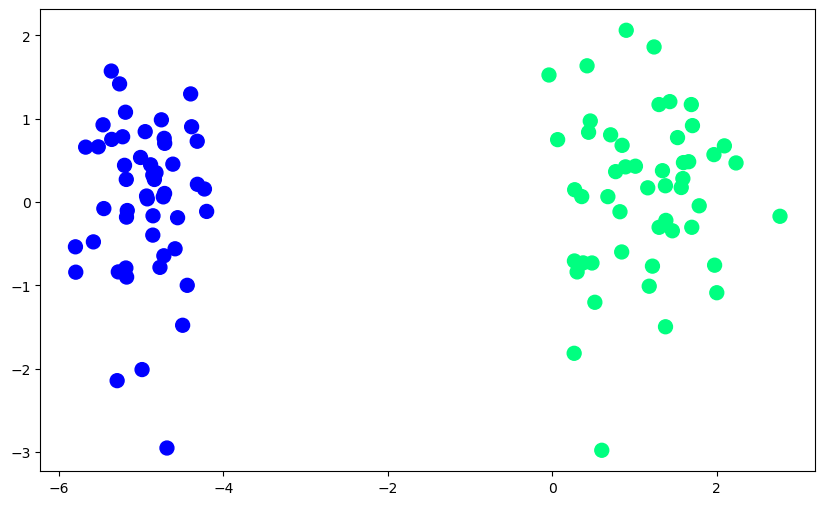

In [98]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)

In [99]:
from sklearn.linear_model import LogisticRegression

In [100]:
lor = LogisticRegression(penalty='none', solver='sag')

In [101]:
lor.fit(X,y)

C:\Users\dell\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1182: FutureWarning: `penalty='none'`has been deprecated in 1.2 and will be removed in 1.4. To keep the past behaviour, set `penalty=None`.
  warnings.warn(
C:\Users\dell\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


LogisticRegression(penalty='none', solver='sag')

In [102]:
lor.coef_

array([[4.1409341 , 0.18559319]])

In [103]:
lor.intercept_

array([4.10942561])

In [104]:
m1 = -(lor.coef_[0][0])/lor.coef_[0][1]

In [105]:
b1 = -(lor.intercept_)/lor.coef_[0][1]

In [106]:
x_input = np.linspace(-3,3,100)

In [107]:
y_input = m1*x_input+b1

In [121]:
def gd(X,y):
    X=np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr =0.5
    for i in range(100000):
        y_hat = sigmoid(np.dot(X,weights))
        weights+=lr*(np.dot((y-y_hat),X)/X.shape[0])
    return weights[1:], weights[0]

In [122]:
def sigmoid(z):
    return 1/(1+np.exp(-z))

In [123]:
coef_, intercept_ = gd(X,y)

In [124]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [125]:
x_input1=np.linspace(-3,3,100)
y_input1=m*x_input1+b

(-3.0, 3.0)

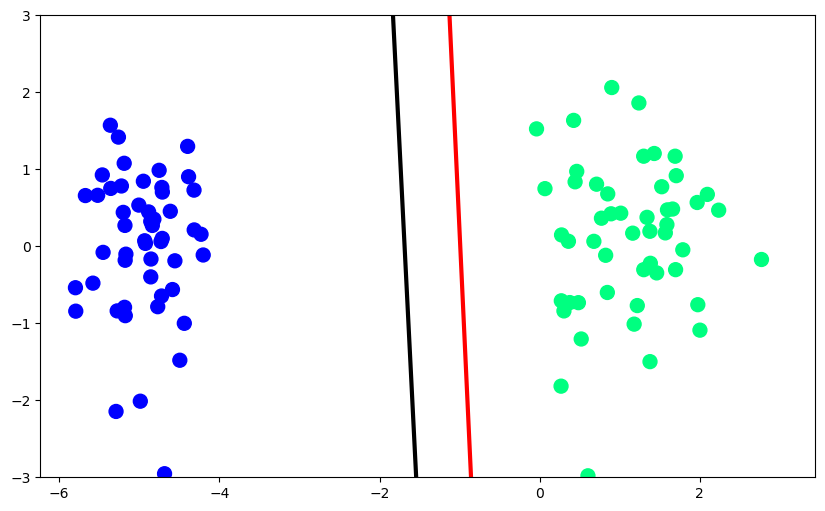

In [126]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input, color='red', linewidth=3)
plt.plot(x_input1,y_input1, color='black', linewidth=3)
plt.scatter(X[:,0], X[:,1], c=y, cmap='winter',s=100)
plt.ylim(-3,3)
